### Step 1: Uploading and Loading the Dataset

In this section, we will load your `BlinkIT Grocery Data.xlsx` dataset into Google Colab. We use `google.colab.files.upload()` to let you choose your local file, and then use Pandas to parse it.

In [1]:
# Import necessary library for file uploading
from google.colab import files
import os

# Prompt you to upload your local Excel file
print("Please upload 'BlinkIT Grocery Data.xlsx' using the button below:")
uploaded = files.upload()


Please upload 'BlinkIT Grocery Data.xlsx' using the button below:


Saving BlinkIT Grocery Data.xlsx to BlinkIT Grocery Data.xlsx


Once the file is uploaded, we will read it using `pd.read_excel()` and inspect its basic structure (dimensions, columns, types, and the first few rows).

In [2]:
import pandas as pd
import numpy as np

file_name = "BlinkIT Grocery Data.xlsx"

if os.path.exists(file_name):
    # Load the Excel file into a pandas DataFrame
    print(f"Loading {file_name}...")
    df = pd.read_excel(file_name)

    # Display basic dimensions of the dataset
    print(f"Success! Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.\n")

    # Display column names and data types
    print("--- Column Names and Data Types ---")
    print(df.info())

    # Preview first 5 rows
    print("\n--- First 5 Rows of the Dataset ---")
    display(df.head())
else:
    print(f"Error: '{file_name}' not found. Please make sure the uploaded file is named exactly '{file_name}'.")


Loading BlinkIT Grocery Data.xlsx...
Success! Dataset loaded with 8523 rows and 12 columns.

--- Column Names and Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


### Objective 1: Understand Business and Sales Performance

In this section, we analyze the basic profile of the dataset: the variety of products, the classifications of outlets, overall sales performance, and consumer satisfaction ratings.

In [5]:
# 1. Exploring Product and Outlet Classifications
print("=== UNIQUE PRODUCT CATEGORIES (Item Type) ===")
print(df['Item Type'].unique())
print(f"Total unique categories: {df['Item Type'].nunique()}\n")

print("=== OUTLET TYPES ===")
print(df['Outlet Type'].unique())

print("\n=== OUTLET LOCATIONS ===")
print(df['Outlet Location Type'].unique())


=== UNIQUE PRODUCT CATEGORIES (Item Type) ===
['Fruits and Vegetables' 'Health and Hygiene' 'Frozen Foods' 'Canned'
 'Soft Drinks' 'Household' 'Snack Foods' 'Meat' 'Breads' 'Hard Drinks'
 'Others' 'Dairy' 'Breakfast' 'Baking Goods' 'Seafood' 'Starchy Foods']
Total unique categories: 16

=== OUTLET TYPES ===
['Supermarket Type1' 'Supermarket Type2' 'Grocery Store'
 'Supermarket Type3']

=== OUTLET LOCATIONS ===
['Tier 1' 'Tier 3' 'Tier 2']


Now, we will compute key overall KPIs (Key Performance Indicators): Total Sales, Average Sales, and Average Rating.

In [4]:
# 2. Calculate Key Sales Metrics
total_sales = df['Sales'].sum()
average_sales = df['Sales'].mean()
average_rating = df['Rating'].mean()

print("=== OVERALL KPI SUMMARY ===")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Average Sales per Transaction: ${average_sales:.2f}")
print(f"Average Customer Rating: {average_rating:.2f} / 5.0")


=== OVERALL KPI SUMMARY ===
Total Sales: $1,201,681.49
Average Sales per Transaction: $140.99
Average Customer Rating: 3.97 / 5.0


Let's visualize the distribution of sales across different product categories and look at which outlet types generate the most revenue.

/tmp/ipykernel_1019/1388353404.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_by_item, x='Sales', y='Item Type', palette='viridis')


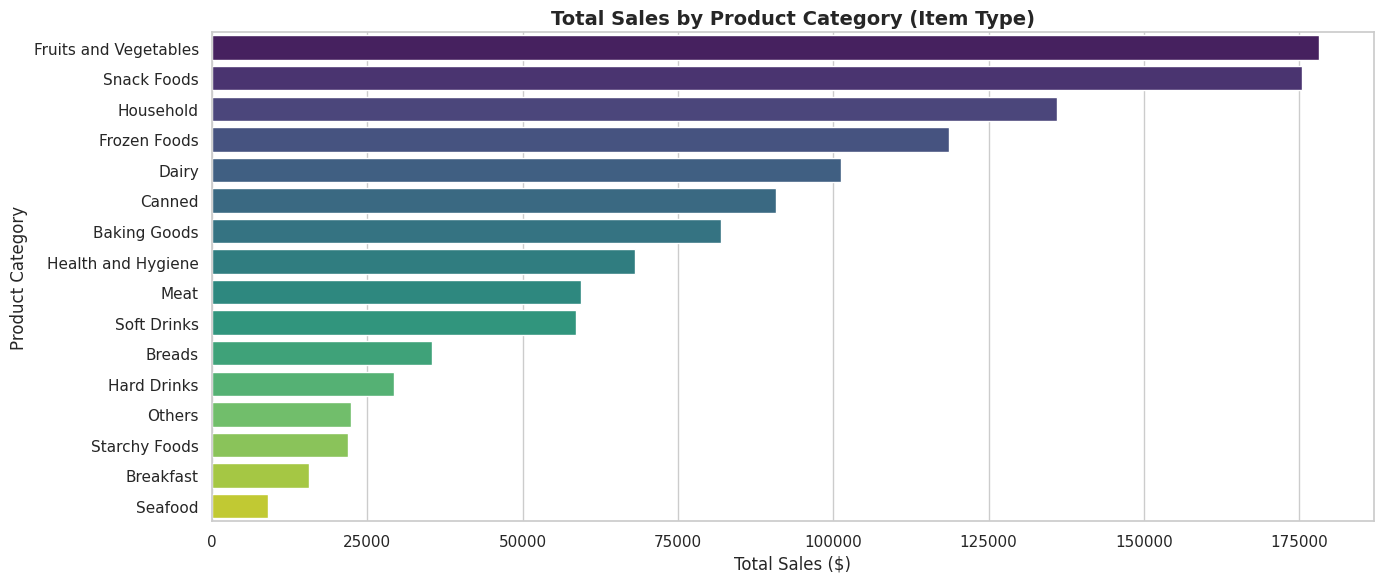

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styles
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Chart 1: Sales by Item Type
sales_by_item = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False).reset_index()

sns.barplot(data=sales_by_item, x='Sales', y='Item Type', palette='viridis')
plt.title('Total Sales by Product Category (Item Type)', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales ($)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.tight_layout()
plt.show()
